In [2]:
import yfinance as yf, pandas as pd, numpy as np, matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm


In [3]:
#Funds
spy = yf.Ticker("SPY").history(start="2010-01-01")
vix = yf.Ticker("^VIX").history(start="2010-01-01")

#Adjust timezones so dates exactly match
spy.index = spy.index.tz_localize(None).normalize()
vix.index = vix.index.tz_localize(None).normalize()



In [4]:
ret = spy['Close'].pct_change()
ann = np.sqrt(252) * 100 # converting daily std to annual
data = pd.DataFrame(index = spy.index)
data["vol_5d"] = ret.rolling(5).std() * ann # 5-day vol
data["vol_21d"] = ret.rolling(21).std() * ann # 21-day vol
data["vol_63d"] = ret.rolling(63).std() * ann # 63-day vol
data["vix"] = vix["Close"] # value at close on day t
data["fwd_vol"] = ret.rolling(5).std().shift(-5) * ann # target: days t+1...t+5
data = data.dropna()

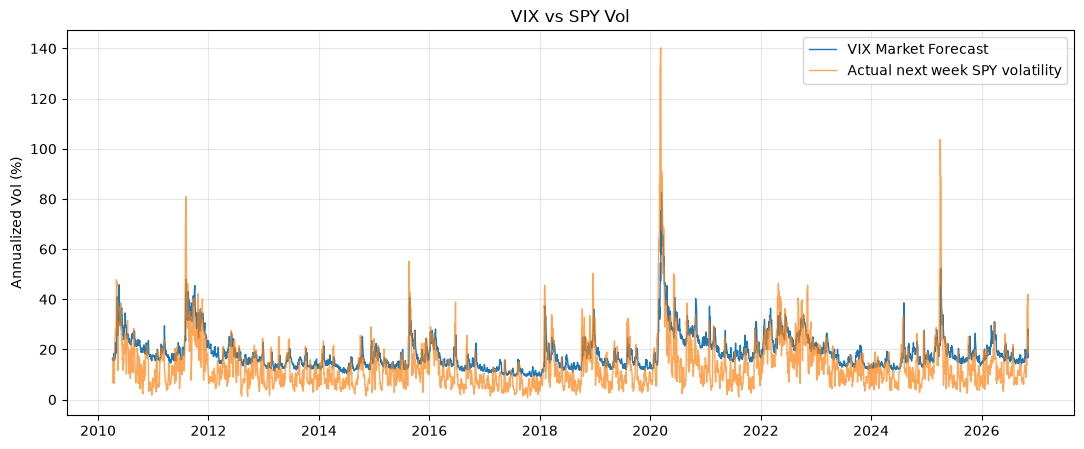

In [5]:
#Plot 1 VIX vs SPY vol
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(data.index, data["vix"], lw = 1, label="VIX Market Forecast")
ax.plot(data.index, data["fwd_vol"], lw = 1, alpha=0.7, label = "Actual next week SPY volatility")
ax.set_ylabel("Annualized Vol (%)")
ax.set_title("VIX vs SPY Vol")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Observations:**
Vix sits above the actual volatility during calm periods.

During spikes actual volatility often exceeds VIX.

Actual volatility is more reactive.

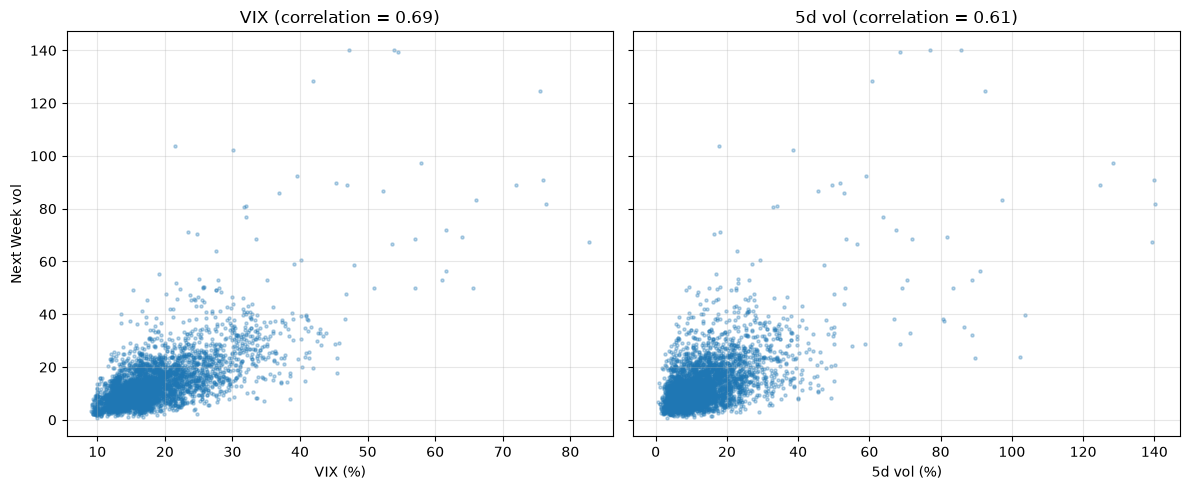

In [6]:
# Plot 2: seeing which predictor fits best with the target
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, col, label in zip(axes, ["vix", "vol_5d"], ["VIX", "5d vol"]):
    ax.scatter(data[col], data["fwd_vol"], s=5, alpha=0.3)
    r = data[col].corr(data["fwd_vol"])
    ax.set_title(f"{label} (correlation = {r:.2f})")
    ax.set_xlabel(f"{label} (%)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Next Week vol")
plt.tight_layout()
plt.show()


**VIX**: 0.70. Vix lines up with the next weeks vol better than past volatility

**Past Week Volatility**: 0.61, still pretty strong but less than VIX

Stock Dataset for each listed stock


In [7]:
# ---- Settings ----
TICKERS = ["AAPL", "MSFT", "JPM", "GS", "XOM", "JNJ", "UNH", "KO",
           "PG", "WMT", "AMZN", "HD", "CAT", "BA"]   # large companies across sectors
START = "2010-07-01"        # all tickers trade over the full period
END = "2022-12-31"          # train through 2022, test 2023 onward
DATA_END = "2026-11-07"
ANN = np.sqrt(252) * 100    # daily std -> annualized % (same units as VIX)


def normalize_dates(index):
    """Remove timezones and times so dates match across all tickers."""
    dates = pd.DatetimeIndex(pd.to_datetime(index))
    if dates.tz is not None:
        dates = dates.tz_localize(None)
    return dates.normalize()


# VIX 
vix = yf.Ticker("^VIX").history(start=START, end = DATA_END)
vix.index = normalize_dates(vix.index)   # match stock data dates
vix_close = vix["Close"]


def build_stock_data(ticker):
    """Predictors and target for one ticker. Each row is one trading day."""
    prices = yf.Ticker(ticker).history(start=START, end=DATA_END)["Close"]
    prices.index = normalize_dates(prices.index)
    daily_ret = prices.pct_change()

    df = pd.DataFrame(index=prices.index)
    df["vol_5d"]  = daily_ret.rolling(5).std() * ANN    # past week
    df["vol_21d"] = daily_ret.rolling(21).std() * ANN   # past month
    df["vol_63d"] = daily_ret.rolling(63).std() * ANN   # past quarter
    df["vix"]     = vix_close                           # VIX at close on day t

    # Target: volatility over the NEXT 5 trading days (t+1 ... t+5)
    df["fwd_vol"] = daily_ret.rolling(5).std().shift(-5) * ANN

    return df.dropna()


# Build each stock's data once 
stock_data = {}
for t in TICKERS:
    stock_data[t] = build_stock_data(t)
    df = stock_data[t]
    print(f"{t}: {len(df)} rows, {df.index[0].date()} to {df.index[-1].date()}")

AAPL: 4046 rows, 2010-09-30 to 2026-10-30
MSFT: 4046 rows, 2010-09-30 to 2026-10-30
JPM: 4046 rows, 2010-09-30 to 2026-10-30
GS: 4046 rows, 2010-09-30 to 2026-10-30
XOM: 4046 rows, 2010-09-30 to 2026-10-30
JNJ: 4046 rows, 2010-09-30 to 2026-10-30
UNH: 4046 rows, 2010-09-30 to 2026-10-30
KO: 4046 rows, 2010-09-30 to 2026-10-30
PG: 4046 rows, 2010-09-30 to 2026-10-30
WMT: 4046 rows, 2010-09-30 to 2026-10-30
AMZN: 4046 rows, 2010-09-30 to 2026-10-30
HD: 4046 rows, 2010-09-30 to 2026-10-30
CAT: 4046 rows, 2010-09-30 to 2026-10-30
BA: 4046 rows, 2010-09-30 to 2026-10-30


In [8]:
#Combined Data Set
spy_df = build_stock_data("SPY")

combined = pd.DataFrame(index=spy_df.index)
combined["spy_vol_5d"] = spy_df["vol_5d"]
combined["spy_vol_21d"] = spy_df["vol_21d"]
combined["spy_vol_63d"] = spy_df["vol_63d"]
combined["vix"] = spy_df["vix"] # Benchmark 

# Each stocks past volatitlty for predicting
for t in TICKERS:
    combined[f"{t}_vol_5d"] = stock_data[t]["vol_5d"]
    combined[f"{t}_vol_21d"] = stock_data[t]["vol_21d"]
    combined[f"{t}_vol_63d"] = stock_data[t]["vol_63d"]

combined["target"] = spy_df["fwd_vol"]
combined = combined.dropna()
print(combined.shape)
combined.head()

(4046, 47)


,spy_vol_5d,spy_vol_21d,spy_vol_63d,vix,AAPL_vol_5d,AAPL_vol_21d,AAPL_vol_63d,MSFT_vol_5d,MSFT_vol_21d,MSFT_vol_63d,...,HD_vol_5d,HD_vol_21d,HD_vol_63d,CAT_vol_5d,CAT_vol_21d,CAT_vol_63d,BA_vol_5d,BA_vol_21d,BA_vol_63d,target
Date,,,,,,,,,,,,,,,,,,,,,
2010-09-30,16.451014,15.683665,18.084383,23.700001,17.224003,20.290442,22.188632,12.931715,24.004189,21.500377,...,19.231016,19.357123,24.938200,36.831900,25.244120,27.837759,25.345342,24.102725,28.491551,16.505402
2010-10-01,6.354594,12.582456,18.029740,22.500000,10.788776,18.967788,22.163083,4.273971,23.358008,21.515363,...,6.894962,17.227070,24.888528,12.674965,21.858705,27.686042,19.129671,23.494470,28.467467,16.594015
2010-10-04,7.696831,12.850677,18.103477,23.530001,11.396808,20.127549,22.370263,11.903811,24.392092,21.384850,...,8.000112,15.771679,24.676208,13.833568,22.811303,27.861514,17.122616,23.192152,28.440852,13.978218
2010-10-05,17.055944,13.816035,17.476195,21.760000,32.942942,21.842871,22.140762,21.732709,24.709904,21.321430,...,6.269772,15.221127,24.270911,27.772772,23.342090,27.340051,25.741461,25.038377,28.557597,4.304118
2010-10-06,16.839954,12.930668,17.396661,21.490000,32.946486,21.660416,22.126122,21.594796,24.207295,21.312643,...,6.269772,13.363455,24.268378,27.524322,23.260607,27.281708,25.220887,23.793794,28.236672,5.683094


Test Train Split Chronologically

In [9]:
train = combined.loc[combined.index <= END] #2010-2022
test = combined.loc[combined.index > END] # 2023+

train = train.iloc[:-5]
X_train = train.drop(columns= 'target')
y_train = train['target']
X_test = test.drop(columns='target')
y_test = test['target']

print(f"Training rows: {len(train)} ({train.index[0].date()} to {train.index[-1].date()})")
print(f"Testing rows: {len(test)} ({test.index[0].date()} to {test.index[-1].date()})")

Training rows: 3080 (2010-09-30 to 2022-12-22)
Testing rows: 961 (2023-01-03 to 2026-10-30)


Summary of the Target


In [10]:
threshold = y_train.quantile(0.75)

#Kept as a separate variable for later use
spy_vol = (combined["target"] > threshold).astype(int)

target_summary = pd.DataFrame({
    "mean_vol %": [y_train.mean(), y_test.mean()],
    "median_vol %": [y_train.median(), y_test.median()],
    "skew": [y_train.skew(), y_test.skew()],
    "pct_vol %": [
        spy_vol.loc[train.index].mean() * 100,
        spy_vol.loc[test.index].mean() * 100
    ]
}, index=["Train (2010-2022)", "Test (2023+)"]).round(2)
print(f"Volatile-week Threshold: {threshold:.2f}%")
target_summary

Volatile-week Threshold: 17.24%


,mean_vol %,median_vol %,skew,pct_vol %
Train (2010-2022),13.79,10.95,3.86,25.00
Test (2023+),12.64,11.33,5.39,17.59


Next Week Volatility


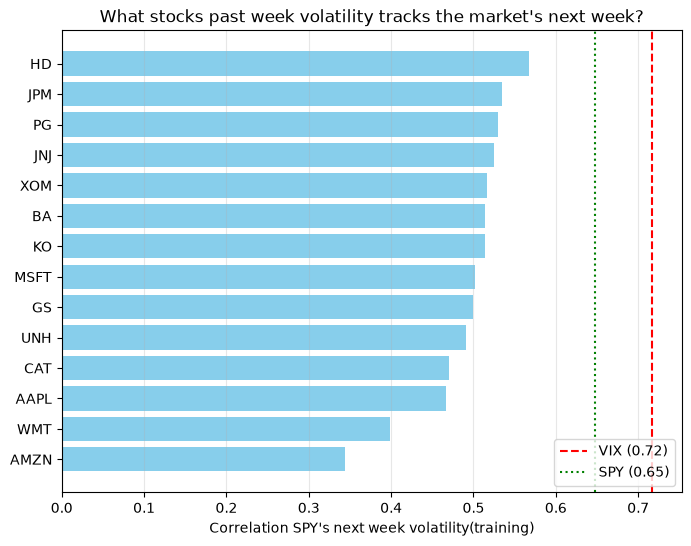

In [11]:
# Which Stock tracks SPY's next week

stock_corr = pd.Series(
    {t: train[f"{t}_vol_5d"].corr(train["target"]) for t in TICKERS}
).sort_values()

vix_corr = train["vix"].corr(train["target"])
spy_corr = train["spy_vol_5d"].corr(train["target"])

fig,ax = plt.subplots(figsize=(8,6))
ax.barh(stock_corr.index, stock_corr.values, color="skyblue")
ax.axvline(vix_corr, color="red", linestyle="--", label=f"VIX ({vix_corr:.2f})")
ax.axvline(spy_corr, color="green", linestyle=":", label=f"SPY ({spy_corr:.2f})")
ax.set_xlabel("Correlation SPY's next week volatility(training)")
ax.set_title("What stocks past week volatility tracks the market's next week?")
ax.legend(loc="lower right")
ax.grid(alpha=0.3, axis="x")
plt.show()

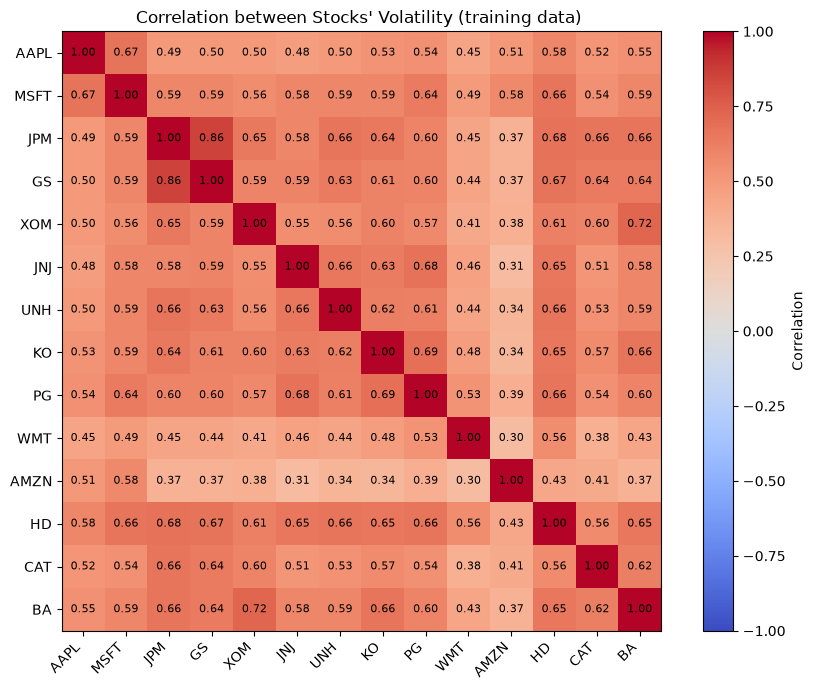

In [25]:
vol_cols = [f"{t}_vol_5d" for t in TICKERS]
stock_vol_corr = train[vol_cols].corr()

fig, ax = plt.subplots(figsize=(9,7))
im = ax.imshow(stock_vol_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(TICKERS)))
ax.set_xticklabels(TICKERS, rotation=45, ha="right")
ax.set_yticks(range(len(TICKERS)))
ax.set_yticklabels(TICKERS)

# Each correlation value inside its square
for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        ax.text(j, i, f"{stock_vol_corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation between Stocks' Volatility (training data) ")
plt.tight_layout()
plt.show()

Every correlation here is positive, this shows that when one stock's volatility rises, SPY's volatility tends to rise too. This is due to market wide sharing affects. Our stocks overlap heavily as predictors.

AMZN and WMT are outliers. Their correlations fall between 0.3 - 0.45, their volatility is more company specific rather than market driven.

Baseline and  Vix Benchmark

In [13]:
BASELINE_COLS = ["spy_vol_5d", "spy_vol_21d", "spy_vol_63d"]

def fit_and_score(cols):
    """
    Fit model and score on given columns
    """
    model = LinearRegression().fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    scores = {"test_MSE": mean_squared_error(y_test, pred),
              "test_R2": r2_score(y_test, pred)
              }
    return scores, model

naive_scores = {"test_MSE": mean_squared_error(y_test, X_test["spy_vol_5d"]),
                "test_R2": r2_score(y_test, X_test["spy_vol_5d"])}

baseline_scores, baseline_model = fit_and_score(BASELINE_COLS)
vix_scores, vix_model = fit_and_score(BASELINE_COLS + ["vix"])

benchmark_table = pd.DataFrame({
    "Naive (next week = last week):": naive_scores,
    "Baseline:": baseline_scores,
    "Vix benchmark:": vix_scores,
}).T.round(3)
benchmark_table


,test_MSE,test_R2
Naive (next week = last week):,84.804,-0.202
Baseline:,62.466,0.115
Vix benchmark:,48.868,0.308


One Stock each time

        test_MSE  test_R2  MSE_reduction_%
ticker                                    
JNJ       59.006    0.164            5.539
KO        61.859    0.123            0.972
PG        61.911    0.123            0.888
XOM       61.990    0.122            0.762
MSFT      62.505    0.114           -0.063
AMZN      62.642    0.112           -0.281
BA        62.965    0.108           -0.799
WMT       62.977    0.108           -0.818
AAPL      63.109    0.106           -1.029
CAT       63.183    0.105           -1.148
JPM       63.320    0.103           -1.368
GS        64.083    0.092           -2.589
HD        64.634    0.084           -3.471
UNH       65.174    0.076           -4.335


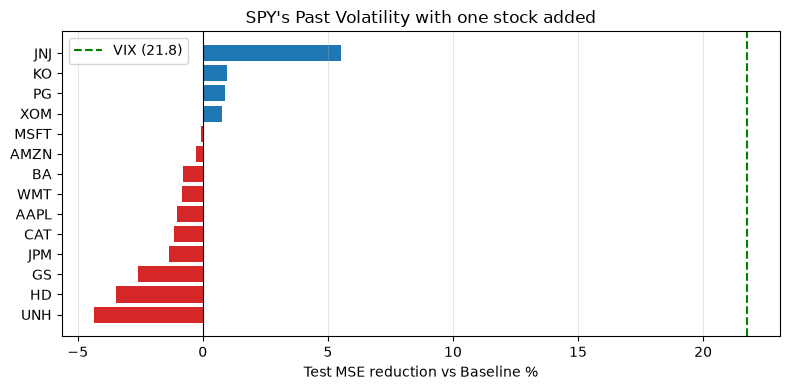

In [14]:
base_mse = baseline_scores["test_MSE"]
rows = []

for t in TICKERS:
    #Baseline + one stock's past volatility
    cols = BASELINE_COLS + [f"{t}_vol_5d", f"{t}_vol_21d", f"{t}_vol_63d"]
    scores,_=fit_and_score(cols)
    rows.append({
        "ticker":t,
        **scores,
        "MSE_reduction_%":(base_mse - scores["test_MSE"])/base_mse*100
    })

stock_rank = (pd.DataFrame(rows)
                  .set_index("ticker")
                  .sort_values("MSE_reduction_%", ascending=False)
                  .round(3))
print(stock_rank)

# Improvement of VIX over baseline
vix_reduction = (base_mse - vix_scores["test_MSE"]) / base_mse * 100

# Rank Chart
plot_data = stock_rank["MSE_reduction_%"].sort_values()
colors = ["tab:blue" if v > 0 else "tab:red" for v in plot_data]

fig, ax = plt.subplots(figsize=(8,4))
ax.barh(plot_data.index, plot_data.values, color=colors)
ax.axvline(vix_reduction, color="green", ls="--", label=f"VIX ({vix_reduction:.1f})")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Test MSE reduction vs Baseline %")
ax.set_title("SPY's Past Volatility with one stock added")
ax.legend(loc="best")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

Loading libraries and tools for the helper fuctions 
TimeSeriesSPlit is used for CV splitting for time series data
Every fold trains on past data and validates on future so the model never sees future info
The gap = 5 is because our target looks 5 trading days ahead, so we skip that many days between train and validation
The helper functions compute test MSE and R^2 and percent improvement over the baseline

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

In [16]:
# Each row is a singular trading day and its target is 5 days ahead
# last targets of a training fold overlap the first days of the next fold
TSCV = TimeSeriesSplit(n_splits=5, gap = 5)
y_tr = np.asarray(y_train)
y_te = np.asarray(y_test)

def score(pred):
    return {"test_MSE": mean_squared_error(y_te, pred),
            "test_R2": r2_score(y_te, pred)
            }
def pct_reduct(mse):
    """Percent drop in test MSE vs baseline"""
    base = baseline_scores["test_MSE"]
    return (base - mse) / base * 100

def stock_of(col):
    """JNJ_vol_21d -> JNJ"""
    return col.split("_")[0]

LOG_ROWS = {} # filled by optional log target cell






### All Stocks with linear regression
We use SPY's past volatility plus the 5, 21, and 63 day volatility for all 14 stocks. The correlation heat map above showed that socks volatility overlap significantly. We expect this model to struggle because when predictors overlap they make coefficients unstable and more likely to be overfit. 

In [17]:
STOCK_COLS = [f"{t}_vol_{w}"for t in TICKERS for w in ("5d", "21d", "63d")]
ALL_STOCK_COLS = BASELINE_COLS + STOCK_COLS # 3 + 14*3 = 45 predictors

allstock_scores, allstock_model = fit_and_score(ALL_STOCK_COLS)

#A Large gap between train and test R^2 is the sign of overfitting

train_R2 = r2_score(y_tr, allstock_model.predict(X_train[ALL_STOCK_COLS]))

print(f"All stocks (OLS): train R² = {train_R2:.3f}, "
      f"test R² = {allstock_scores['test_R2']:.3f}")
print(f"Test MSE reduction vs. baseline: "
      f"{pct_reduct(allstock_scores['test_MSE']):.1f}%")


# Correlated predictors = unstable coefficients
ols_coefs = pd.Series(allstock_model.coef_, index=ALL_STOCK_COLS)
print("\nJPM and GS coefficients in all stocks OLS model")
print(ols_coefs[[c for c in STOCK_COLS if stock_of(c) in ("JPM", "GS")]].round(3))




All stocks (OLS): train R² = 0.486, test R² = -0.137
Test MSE reduction vs. baseline: -28.4%

JPM and GS coefficients in all stocks OLS model
JPM_vol_5d     0.009
JPM_vol_21d    0.069
JPM_vol_63d   -0.182
GS_vol_5d     -0.028
GS_vol_21d    -0.093
GS_vol_63d    -0.035
dtype: float64


Using all observed stocks with linear regression fits training data well(R2 =0.486) but then it fails on the test period (R2 = -0.139) raising MSE above the baseline 28%. This shows overfitting due to correlated predictors.

In [23]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

TSCV = TimeSeriesSplit(n_splits=5, gap=5)   # this splits time series data for CV

Best alpha (lambda): 0.5569
Lasso test MSE = 58.74,R2 = 0.168reduction vs. baseline = 6.0%


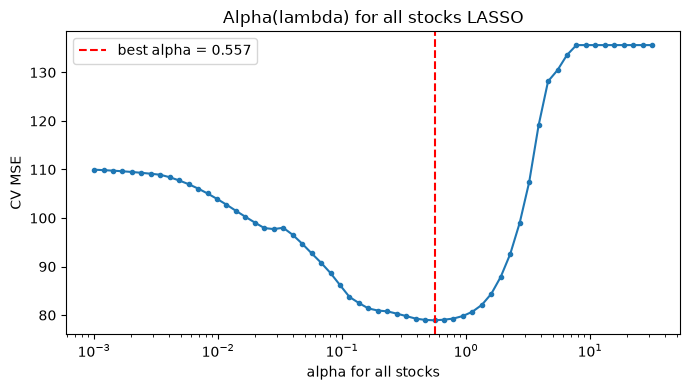

In [24]:
def fit_lasso_cv(cols, y=None, alphas=np.logspace(-3,1.5,60)):
    """"Standardizing + LASSO, choosing lambda (alpha) via CV"""
    y = y_tr if y is None else y
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('lasso', Lasso(max_iter=100_000)),
    ])

    search = GridSearchCV(pipe, {"lasso__alpha": alphas}, cv=TSCV,
                          scoring = 'neg_mean_squared_error')
    search.fit(X_train[cols],y)
    return search

lasso_search = fit_lasso_cv(ALL_STOCK_COLS)
best_alpha = lasso_search.best_params_['lasso__alpha']
lasso_scores = score(lasso_search.predict(X_test[ALL_STOCK_COLS]))

print(f"Best alpha (lambda): {best_alpha:.4f}")
print(f"Lasso test MSE = {lasso_scores['test_MSE']:.2f},"
      f"R2 = {lasso_scores['test_R2']:.3f}"
      f"reduction vs. baseline = {pct_reduct(lasso_scores['test_MSE']):.1f}%")

# CV error: shows how alpha was chosen
alphas = np.array(lasso_search.cv_results_["param_lasso__alpha"], dtype = float)
cv_mse = -lasso_search.cv_results_["mean_test_score"]

fig, ax = plt.subplots(figsize=(7,4))
ax.semilogx(alphas,cv_mse,marker=".")
ax.axvline(best_alpha, color = "red", ls = "--", label = f"best alpha = {best_alpha:.3g}")
ax.set_xlabel("alpha for all stocks")
ax.set_ylabel("CV MSE")
ax.set_title("Alpha(lambda) for all stocks LASSO")
ax.legend()
plt.tight_layout()
plt.show()

Our CV error is a U-shape with a large penalty. The minimum is at alpha = 0.557 which is well inside the range. Lasso also reduces MSE by 6% relative to the baseline. 

The cells list the predictos lasso kept as well as combines each stock's three windows into a number for easier comparison. This helps see which stocks matter most.

Lasso kept 10 of 45 predictors:
spy_vol_5d      3.618
spy_vol_21d     1.416
PG_vol_5d       0.728
JNJ_vol_5d      0.554
HD_vol_5d       0.408
spy_vol_63d     0.342
XOM_vol_5d      0.292
AAPL_vol_21d    0.280
UNH_vol_21d     0.192
AMZN_vol_63d    0.113
dtype: float64

Kept stocks: ['AAPL', 'AMZN', 'HD', 'JNJ', 'PG', 'UNH', 'XOM']
Prediction: at most one of JPM/GS -> True
Prediction: JNJ kept -> True
Prediction: KO and PG dropped -> False

       total_|coef|  kept_in_folds_(of_5)
PG           0.728                     1
JNJ          0.554                     1
HD           0.408                     2
XOM          0.292                     5
AAPL         0.280                     2
UNH          0.192                     5
AMZN         0.113                     0
JPM          0.000                     1
MSFT         0.000                     1
GS           0.000                     0
WMT          0.000                     0
KO           0.000                     1
CAT          0.000      

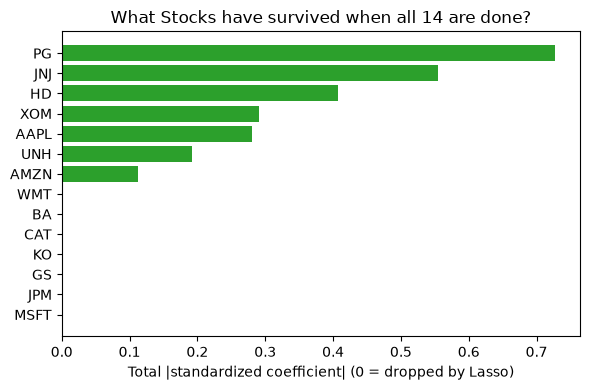

      total_|coef|  kept_in_folds_(of_5)
PG           0.728                     1
JNJ          0.554                     1
HD           0.408                     2
XOM          0.292                     5
AAPL         0.280                     2
UNH          0.192                     5
AMZN         0.113                     0
JPM          0.000                     1
MSFT         0.000                     1
GS           0.000                     0
WMT          0.000                     0
KO           0.000                     1
CAT          0.000                     4
BA           0.000                     3


In [20]:
# Which stocks does lasso keep?

lasso_coefs = pd.Series(
    lasso_search.best_estimator_.named_steps["lasso"].coef_,
    index=ALL_STOCK_COLS)

kept = lasso_coefs[lasso_coefs != 0]
print(f"Lasso kept {len(kept)} of {len(ALL_STOCK_COLS)} predictors:")
print(kept.sort_values(key=abs, ascending=False).round(3))

# one number for a stock: total coefficient over its 5/21/63 day windows
by_stock = (lasso_coefs[STOCK_COLS].abs()
            .groupby(stock_of).sum()
            .reindex(TICKERS))
kept_stocks = set(by_stock[by_stock > 0].index)

print("\nKept stocks:", sorted(kept_stocks))
print("Prediction: at most one of JPM/GS ->",
       len({"JPM", "GS"} & kept_stocks) <= 1)
print("Prediction: JNJ kept ->", "JNJ" in kept_stocks)
print("Prediction: KO and PG dropped ->", not({"KO", "PG"}& kept_stocks))



#Checking for stability: repeat lasso on subsets its pick can be arbitrary 
# so we refit at a chosen lambda over each CV training window and see how often each stock survives
selection_count = pd.Series(0, index=TICKERS)
for tr_idx, _ in TSCV.split(X_train):
    m = Pipeline([("scale", StandardScaler()),
                  ("lasso", Lasso(alpha = best_alpha, max_iter = 100_000))])
    m.fit(X_train[ALL_STOCK_COLS].iloc[tr_idx], y_tr[tr_idx])
    c = pd.Series(m.named_steps["lasso"].coef_, index=ALL_STOCK_COLS)
    selection_count += (c.abs().groupby(stock_of).sum() > 0).reindex(TICKERS).astype(int)

summary = pd.DataFrame({"total_|coef|": by_stock.round(3),
                            f"kept_in_folds_(of_{TSCV.n_splits})": selection_count})
print("\n", summary.sort_values("total_|coef|", ascending=False))

plot_data = by_stock.sort_values()
fig, ax = plt.subplots(figsize=(6,4))
ax.barh(plot_data.index, plot_data.values,
        color=["tab:green" if v > 0 else "tab:gray" for v in plot_data])
ax.set_xlabel("Total |standardized coefficient| (0 = dropped by Lasso)")
ax.set_title("What Stocks have survived when all 14 are done?")
plt.tight_layout()
plt.show()
print(summary.sort_values("total_|coef|", ascending=False).to_string())

In [22]:
for k, (tr_idx, _) in enumerate(TSCV.split(X_train), 1):
    m = Pipeline([("scale", StandardScaler()),
                  ("lasso", Lasso(alpha=best_alpha, max_iter=100_000))])

    
    m.fit(X_train[ALL_STOCK_COLS].iloc[tr_idx], y_tr[tr_idx])
    c = pd.Series(m.named_steps["lasso"].coef_, index=ALL_STOCK_COLS)[STOCK_COLS]
    kept_here = sorted(set(stock_of(col) for col in c[c != 0].index))
    print(f"Fold {k}: trained through {X_train.index[tr_idx[-1]].date()} -> {kept}")

Fold 1: trained through 2012-10-05 -> spy_vol_5d      3.617658
spy_vol_21d     1.415742
spy_vol_63d     0.341986
AAPL_vol_21d    0.280090
XOM_vol_5d      0.291522
JNJ_vol_5d      0.554001
UNH_vol_21d     0.191870
PG_vol_5d       0.727616
AMZN_vol_63d    0.112569
HD_vol_5d       0.407713
dtype: float64
Fold 2: trained through 2014-10-22 -> spy_vol_5d      3.617658
spy_vol_21d     1.415742
spy_vol_63d     0.341986
AAPL_vol_21d    0.280090
XOM_vol_5d      0.291522
JNJ_vol_5d      0.554001
UNH_vol_21d     0.191870
PG_vol_5d       0.727616
AMZN_vol_63d    0.112569
HD_vol_5d       0.407713
dtype: float64
Fold 3: trained through 2016-11-03 -> spy_vol_5d      3.617658
spy_vol_21d     1.415742
spy_vol_63d     0.341986
AAPL_vol_21d    0.280090
XOM_vol_5d      0.291522
JNJ_vol_5d      0.554001
UNH_vol_21d     0.191870
PG_vol_5d       0.727616
AMZN_vol_63d    0.112569
HD_vol_5d       0.407713
dtype: float64
Fold 4: trained through 2018-11-16 -> spy_vol_5d      3.617658
spy_vol_21d     1.415742
spy